# Per-Family Probe Evaluation

Loads trained MC-STGAT-IDS encoders and evaluates them with **one binary
logistic regression per attack family** (family vs. Benign), plus an
optional multi-class probe.

**No retraining.** The encoder is frozen; only the downstream classifier is
fit. Runs in ~1–2 minutes per dataset on GPU (dominated by the embedding pass).

**Why per-family:** the aggregate binary probe has one decision boundary
that must serve DDoS, DoS, Reconnaissance, and Theft simultaneously. For
heterogeneous classes this is a compromise. Per-family probes let each class
get its own threshold and coefficient weights — the standard operational
model in Snort/Suricata and the correct way to report per-class FNR.

**Outputs:**
- `per_family_probe_results.json` — FNR/FPR/F1/PR-AUC per family per dataset
- `per_family_plots/` — per-dataset bar charts and confusion matrices

**Requirements:**
- SSL checkpoints from `ssl_byol_final.ipynb` (encoder_state_dict + config)
- Graph pickles from `graph_build_final.ipynb`
- `norm_stats.json` alongside the pickles

**Note:** this notebook re-defines `GATEncoder`, `embed_graphs`, and
`dominant_family` so it runs standalone. The definitions must match the
SSL notebook exactly — otherwise `load_state_dict` will fail.

## Cell 1 — Imports

In [1]:
import os, json, pickle, gc, contextlib, warnings
from collections import Counter
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Batch
from torch_geometric.nn import GATConv, GlobalAttention
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, f1_score, roc_curve,
                             average_precision_score, classification_report)
import pandas as pd
warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cuda


## Cell 2 — Configuration

In [2]:
DATASETS = ['gotham', 'nf_ton', 'nf_bot']

ATTACK_THRESHOLD = 0
MIN_TRAIN_POS    = 5     # skip family if fewer positives in train
MIN_TEST_POS     = 3     # skip family if fewer positives in test
PRINT_VERBOSE    = True

SSL_METHOD = 'moco'   # or 'moco'

# Output paths
RESULTS_JSON = f'per_family_probe_results_{SSL_METHOD}.json'
PLOT_ROOT    = 'per_family_plots'
os.makedirs(PLOT_ROOT, exist_ok=True)

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
print('Config ready.')



Config ready.


## Cell 3 — Dataset registry + family merger

In [3]:
def gotham_family_merger(lbl):
    if lbl.startswith('Merlin'): return 'Merlin'
    if lbl.startswith('Mirai'):  return 'Mirai'
    return lbl

DATASET_CONFIG = {
    'gotham': {
        'dir': 'Gotham_processed_features_10s/graphs',
        'attack_threshold': ATTACK_THRESHOLD,
        'label_merge_fn': gotham_family_merger,
    },
    'nf_ton': {
        'dir': 'NFToNIoT_v3_10s/graphs',
        'attack_threshold': ATTACK_THRESHOLD,
        'label_merge_fn': None,
    },
    'nf_bot': {
        'dir': 'NFBoTIoT_v3_10s/graphs',
        'attack_threshold': ATTACK_THRESHOLD,
        'label_merge_fn': None,
    },
}

for k, v in DATASET_CONFIG.items():
    print(f"  {k:<8}  thresh={v['attack_threshold']}  "
          f"merge={'yes' if v['label_merge_fn'] else 'no'}")

  gotham    thresh=0  merge=yes
  nf_ton    thresh=0  merge=no
  nf_bot    thresh=0  merge=no


## Cell 4 — Autocast helper

In [4]:
if DEVICE.type == 'cuda':
    try:
        from torch.amp import autocast as _ac
        def autocast_ctx(): return _ac(device_type='cuda', dtype=torch.float16)
    except Exception:
        from torch.cuda.amp import autocast as _ac
        def autocast_ctx(): return _ac(enabled=True)
else:
    def autocast_ctx(): return contextlib.nullcontext()

## Cell 5 — Encoder (must match the SSL notebook exactly)

In [5]:
class GATEncoder(nn.Module):
    def __init__(self, in_ch, hid, heads, layers, edge_dim):
        super().__init__()
        self.convs = nn.ModuleList(); self.bns = nn.ModuleList()
        self.convs.append(GATConv(in_ch, hid, heads=heads, edge_dim=edge_dim,
                                  concat=True, dropout=0.0))
        self.bns.append(nn.BatchNorm1d(hid * heads))
        for _ in range(layers - 2):
            self.convs.append(GATConv(hid * heads, hid, heads=heads,
                                      edge_dim=edge_dim, concat=True, dropout=0.0))
            self.bns.append(nn.BatchNorm1d(hid * heads))
        self.convs.append(GATConv(hid * heads, hid, heads=1, edge_dim=edge_dim,
                                  concat=False, dropout=0.0))
        self.bns.append(nn.BatchNorm1d(hid))
        self.edge_dim = edge_dim
        self.pool_gate = nn.Sequential(
            nn.Linear(hid, hid), nn.ReLU(), nn.Linear(hid, 1))

    def forward(self, x, ei, ea=None, b=None, return_nodes=False):
        for i, c in enumerate(self.convs):
            x = c(x, ei, edge_attr=ea) if (ea is not None and self.edge_dim > 0) \
                else c(x, ei)
            x = F.relu(self.bns[i](x))
        h = GlobalAttention(self.pool_gate)(x, b)
        if return_nodes:
            return x, h
        return h

print('Encoder class ready.')

Encoder class ready.


## Cell 6 — Bundle loader (mirrors SSL notebook; no SSL, just load)

In [6]:
BUNDLES = {}

def dominant_family(g, attack_threshold=0.10, label_merge_fn=None,
                    blacklist=('Unknown', 'unknown', 'UNKNOWN')):
    names = getattr(g, 'edge_attack_names', None)
    if not names:
        lbl = 'Benign'
    else:
        c = Counter(names); total = sum(c.values())
        atk = {k: v for k, v in c.items() if k != 'Benign' and k not in blacklist}
        if not atk or sum(atk.values()) / max(total, 1) < attack_threshold:
            lbl = 'Benign'
        else:
            lbl = max(atk, key=atk.get)
    if label_merge_fn is not None:
        lbl = label_merge_fn(lbl)
    return lbl


def cap_graph(g, max_nodes=128, max_edges=20000):
    g = g.clone(); num_nodes = g.num_nodes
    if g.edge_index.size(1) > max_edges:
        keep = torch.randperm(g.edge_index.size(1))[:max_edges]
        g.edge_index = g.edge_index[:, keep]
        if g.edge_attr is not None and g.edge_attr.size(0) > 0:
            if g.edge_attr.dim() > 2:
                g.edge_attr = g.edge_attr.view(-1, g.edge_attr.size(-1))
            g.edge_attr = g.edge_attr[keep]
    if num_nodes > max_nodes:
        deg = torch.zeros(num_nodes, dtype=torch.long)
        deg.scatter_add_(0, g.edge_index[0],
                         torch.ones(g.edge_index.size(1), dtype=torch.long))
        kn = torch.topk(deg, max_nodes).indices
        mask = torch.zeros(num_nodes, dtype=torch.bool); mask[kn] = True
        s, d = g.edge_index; keep_e = mask[s] & mask[d]
        g.edge_index = g.edge_index[:, keep_e]
        if g.edge_attr is not None and g.edge_attr.size(0) > 0:
            g.edge_attr = g.edge_attr[keep_e]
        remap = torch.zeros(num_nodes, dtype=torch.long)
        remap[mask] = torch.arange(max_nodes, dtype=torch.long)
        g.edge_index = remap[g.edge_index]; g.x = g.x[mask]
    return g


def load_dataset_bundle(DATASET_NAME, force_reload=False):
    if (not force_reload) and DATASET_NAME in BUNDLES:
        print(f"[cache] bundle '{DATASET_NAME}' already loaded")
        return BUNDLES[DATASET_NAME]

    cfg = DATASET_CONFIG[DATASET_NAME]
    DATA_DIR = cfg['dir']
    CHECKPOINT_DIR = os.path.join(DATA_DIR, f'ssl_checkpoints_{SSL_METHOD}')
    encoder_path = os.path.join(CHECKPOINT_DIR, 'ssl_encoder_best.pth')

    if not os.path.isfile(encoder_path):
        raise FileNotFoundError(
            f"No checkpoint at {encoder_path}. Run the SSL notebook first.")

    attack_threshold = cfg['attack_threshold']
    label_merge_fn   = cfg['label_merge_fn']
    print(f"\nLoading bundle — {DATASET_NAME}")
    print(f"  threshold={attack_threshold}  "
          f"merge={'yes' if label_merge_fn else 'no'}")

    def load_graphs(split):
        with open(os.path.join(DATA_DIR, f'{split}_graphs.pkl'), 'rb') as f:
            return pickle.load(f)

    train_graphs = [cap_graph(g) for g in load_graphs('train')]
    val_graphs   = [cap_graph(g) for g in load_graphs('val')]
    test_graphs  = [cap_graph(g) for g in load_graphs('test')]
    print(f"  loaded train={len(train_graphs)} "
          f"val={len(val_graphs)} test={len(test_graphs)}")

    # Normalize features using training statistics
    with open(os.path.join(DATA_DIR, 'norm_stats.json')) as f:
        ns = json.load(f)
    N_CONT    = ns['n_continuous_edge_feats']
    node_mean = torch.tensor(ns['node_mean'], dtype=torch.float)
    node_std  = torch.tensor(ns['node_std'],  dtype=torch.float)
    edge_mean = torch.tensor(ns['edge_mean'], dtype=torch.float)
    edge_std  = torch.tensor(ns['edge_std'],  dtype=torch.float)

    def normalise(graphs):
        for g in graphs:
            g.x = torch.clamp((g.x - node_mean) / (node_std + 1e-8), -10, 10)
            if g.edge_attr is not None and g.edge_attr.size(0) > 0:
                if g.edge_attr.dim() > 2:
                    g.edge_attr = g.edge_attr.view(-1, g.edge_attr.size(-1))
                c, p = g.edge_attr[:, :N_CONT], g.edge_attr[:, N_CONT:]
                c = torch.clamp((c - edge_mean) / (edge_std + 1e-8), -10, 10)
                g.edge_attr = torch.cat([c, p], dim=1)
            if g.edge_attr is None or g.edge_attr.size(0) == 0:
                g.edge_attr = torch.zeros((g.edge_index.size(1), N_CONT),
                                          dtype=torch.float)
            g.x = torch.nan_to_num(g.x, nan=0.0, posinf=0.0, neginf=0.0)
            g.edge_attr = torch.nan_to_num(g.edge_attr, nan=0.0,
                                           posinf=0.0, neginf=0.0)

    normalise(train_graphs); normalise(val_graphs); normalise(test_graphs)

    def is_attack(g):
        return 0 if dominant_family(g, attack_threshold,
                                     label_merge_fn) == 'Benign' else 1

    train_bin = np.array([is_attack(g) for g in train_graphs], dtype=np.int64)
    val_bin   = np.array([is_attack(g) for g in val_graphs],   dtype=np.int64)
    test_bin  = np.array([is_attack(g) for g in test_graphs],  dtype=np.int64)
    print(f"  attack rate : train={train_bin.mean():.3f} "
          f"val={val_bin.mean():.3f} test={test_bin.mean():.3f}")

    bundle = {
        'name': DATASET_NAME,
        'attack_threshold': attack_threshold,
        'label_merge_fn': label_merge_fn,
        'train_graphs': train_graphs, 'val_graphs': val_graphs,
        'test_graphs': test_graphs,
        'train_bin': train_bin, 'val_bin': val_bin, 'test_bin': test_bin,
        'N_CONT': N_CONT, 'encoder_path': encoder_path,
    }
    BUNDLES[DATASET_NAME] = bundle
    print(f"  bundle ready.")
    return bundle

print('Bundle loader ready.')

Bundle loader ready.


## Cell 7 — Embedding + threshold helpers

In [7]:
@torch.inference_mode()
def embed_graphs(encoder, graphs, device, batch_size=64):
    encoder.eval()
    chunks = []; i = 0; cur_bs = batch_size
    while i < len(graphs):
        chunk = graphs[i:i + cur_bs]
        try:
            batch = Batch.from_data_list(chunk).to(device)
            with autocast_ctx():
                out = encoder(batch.x, batch.edge_index,
                              batch.edge_attr, batch.batch)
            if isinstance(out, tuple): out = out[-1]
            arr = out.float().cpu().numpy()
            arr = np.nan_to_num(arr, nan=0.0, posinf=100.0, neginf=-100.0)
            chunks.append(arr)
            del batch, out
            i += cur_bs
            if device.type == 'cuda': torch.cuda.empty_cache()
        except RuntimeError as e:
            if 'out of memory' in str(e).lower() and cur_bs > 1:
                torch.cuda.empty_cache()
                cur_bs = max(1, cur_bs // 2); continue
            raise
    return np.vstack(chunks)


def _balanced_accuracy_threshold(prob, y):
    """Threshold maximizing (TPR + TNR) / 2 on the given split."""
    prob = np.asarray(prob); y = np.asarray(y)
    if len(set(y)) < 2:
        return 0.5, 0.0
    fpr, tpr, thr = roc_curve(y, prob)
    ba = 0.5 * (tpr + (1.0 - fpr))
    idx = int(np.argmax(ba))
    return float(thr[idx]), float(ba[idx])


def _load_encoder(encoder_path):
    ckpt = torch.load(encoder_path, map_location=DEVICE)
    enc = GATEncoder(ckpt['node_dim'], ckpt['hidden_dim'],
                     ckpt['num_heads'], ckpt['num_layers'],
                     ckpt['edge_dim']).to(DEVICE)
    enc.load_state_dict(ckpt['encoder_state_dict']); enc.eval()
    return enc, ckpt

print('Embedding + threshold helpers ready.')

Embedding + threshold helpers ready.


## Cell 8 — Per-family binary probe

In [8]:
def per_family_probe(bundle, verbose=True):
    """One binary LR per attack family (family vs Benign).
    Threshold via balanced accuracy on val. Reports FNR/FPR/F1/PR-AUC."""
    enc, ckpt = _load_encoder(bundle['encoder_path'])

    X_tr = embed_graphs(enc, bundle['train_graphs'], DEVICE)
    X_va = embed_graphs(enc, bundle['val_graphs'],   DEVICE)
    X_te = embed_graphs(enc, bundle['test_graphs'],  DEVICE)

    sc = StandardScaler().fit(X_tr)
    Xtr_s = sc.transform(X_tr)
    Xva_s = sc.transform(X_va)
    Xte_s = sc.transform(X_te)

    thr_lbl  = bundle['attack_threshold']
    merge_fn = bundle.get('label_merge_fn', None)
    fam_tr = np.array([dominant_family(g, thr_lbl, merge_fn)
                       for g in bundle['train_graphs']])
    fam_va = np.array([dominant_family(g, thr_lbl, merge_fn)
                       for g in bundle['val_graphs']])
    fam_te = np.array([dominant_family(g, thr_lbl, merge_fn)
                       for g in bundle['test_graphs']])

    families = sorted(set(fam_te) - {'Benign'})
    if verbose:
        print(f"\n{'='*88}")
        print(f"PER-FAMILY PROBE — {bundle['name']}")
        print(f"{'='*88}")
        print(f"{'family':<20} {'n_tr':>6} {'n_va':>6} {'n_te':>6} "
              f"{'thr':>8} {'FNR':>8} {'FPR':>8} {'F1':>8} {'PR-AUC':>8}")
        print('-' * 88)

    results = {}
    for family in families:
        mask_tr = (fam_tr == family) | (fam_tr == 'Benign')
        mask_va = (fam_va == family) | (fam_va == 'Benign')
        mask_te = (fam_te == family) | (fam_te == 'Benign')

        y_tr = (fam_tr[mask_tr] == family).astype(int)
        y_va = (fam_va[mask_va] == family).astype(int)
        y_te = (fam_te[mask_te] == family).astype(int)

        n_tr_pos = int(y_tr.sum())
        n_va_pos = int(y_va.sum())
        n_te_pos = int(y_te.sum())

        if n_tr_pos < MIN_TRAIN_POS or n_te_pos < MIN_TEST_POS \
                or len(set(y_tr)) < 2 or len(set(y_va)) < 2:
            if verbose:
                print(f"{family:<20} {n_tr_pos:>6} {n_va_pos:>6} {n_te_pos:>6}  "
                      f"(skip: too few positive samples)")
            continue

        lr = LogisticRegression(max_iter=3000, n_jobs=-1)
        lr.fit(Xtr_s[mask_tr], y_tr)

        p_va = lr.predict_proba(Xva_s[mask_va])[:, 1]
        p_te = lr.predict_proba(Xte_s[mask_te])[:, 1]

        thr, ba = _balanced_accuracy_threshold(p_va, y_va)
        pred = (p_te >= thr).astype(int)

        tn, fp, fn, tp = confusion_matrix(y_te, pred, labels=[0, 1]).ravel()
        fnr = fn / max(fn + tp, 1)
        fpr = fp / max(fp + tn, 1)
        f1  = 2 * tp / max(2 * tp + fp + fn, 1)
        try:
            pr_auc = float(average_precision_score(y_te, p_te))
        except Exception:
            pr_auc = float('nan')

        if verbose:
            print(f"{family:<20} {n_tr_pos:>6} {n_va_pos:>6} {n_te_pos:>6} "
                  f"{thr:>8.4f} {fnr:>8.4f} {fpr:>8.4f} {f1:>8.4f} "
                  f"{pr_auc:>8.4f}")

        results[family] = {
            'threshold': float(thr),
            'val_balanced_accuracy': float(ba),
            'n_train_pos': n_tr_pos,
            'n_val_pos': n_va_pos,
            'n_test_pos': n_te_pos,
            'FNR': float(fnr),
            'FPR': float(fpr),
            'F1':  float(f1),
            'PR_AUC': pr_auc,
        }

    if results:
        mean_f1  = float(np.mean([r['F1']  for r in results.values()]))
        mean_fnr = float(np.mean([r['FNR'] for r in results.values()]))
        mean_fpr = float(np.mean([r['FPR'] for r in results.values()]))
        mean_pra = float(np.nanmean([r['PR_AUC'] for r in results.values()]))
        if verbose:
            print('-' * 88)
            print(f"{'MACRO AVG':<20} {'':>6} {'':>6} {'':>6} {'':>8} "
                  f"{mean_fnr:>8.4f} {mean_fpr:>8.4f} {mean_f1:>8.4f} "
                  f"{mean_pra:>8.4f}")
            print('=' * 88)
        summary = dict(mean_FNR=mean_fnr, mean_FPR=mean_fpr,
                       mean_F1=mean_f1, mean_PR_AUC=mean_pra)
    else:
        summary = {}

    del enc
    gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()

    return {'per_family': results, 'summary': summary}

print('Per-family probe ready.')

Per-family probe ready.


## Cell 9 — Multi-class probe (optional extension)

In [9]:
def multiclass_probe(bundle, verbose=True):
    """Single multi-class LR over all families (incl. Benign).
    Reports classification_report + confusion matrix."""
    enc, ckpt = _load_encoder(bundle['encoder_path'])

    X_tr = embed_graphs(enc, bundle['train_graphs'], DEVICE)
    X_te = embed_graphs(enc, bundle['test_graphs'],  DEVICE)
    sc = StandardScaler().fit(X_tr)

    thr_lbl  = bundle['attack_threshold']
    merge_fn = bundle.get('label_merge_fn', None)
    fam_tr = [dominant_family(g, thr_lbl, merge_fn) for g in bundle['train_graphs']]
    fam_te = [dominant_family(g, thr_lbl, merge_fn) for g in bundle['test_graphs']]

    lr = LogisticRegression(max_iter=3000, n_jobs=-1)
    lr.fit(sc.transform(X_tr), fam_tr)
    pred = lr.predict(sc.transform(X_te))

    labels = sorted(set(fam_te) | set(pred))
    cm = confusion_matrix(fam_te, pred, labels=labels)

    if verbose:
        print(f"\n{'='*88}")
        print(f"MULTI-CLASS PROBE — {bundle['name']}")
        print(f"{'='*88}")
        print(classification_report(fam_te, pred, labels=labels,
                                    digits=4, zero_division=0))
        print("Confusion matrix (rows=true, cols=pred):")
        print(pd.DataFrame(cm, index=labels, columns=labels))
        # Normalized
        cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
        print("\nRow-normalized (recall per class):")
        print(pd.DataFrame(np.round(cmn, 3), index=labels, columns=labels))

    macro_f1 = f1_score(fam_te, pred, average='macro', zero_division=0)
    weighted_f1 = f1_score(fam_te, pred, average='weighted', zero_division=0)
    if verbose:
        print(f"\nmacro F1 = {macro_f1:.4f}   weighted F1 = {weighted_f1:.4f}")

    out = {
        'macro_F1': float(macro_f1),
        'weighted_F1': float(weighted_f1),
        'labels': labels,
        'confusion_matrix': cm.tolist(),
        'confusion_matrix_normalized': cmn.tolist(),
    }
    del enc
    gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()
    return out

print('Multi-class probe ready.')

Multi-class probe ready.


## Cell 10 — Run per-family probe for all datasets

In [10]:
PER_FAMILY_RESULTS = {}

for ds in DATASETS:
    try:
        b = load_dataset_bundle(ds)
    except FileNotFoundError as e:
        print(f"[skip] {ds}: {e}"); continue
    print(f"\n{'#'*88}\n# {ds.upper()}\n{'#'*88}")
    PER_FAMILY_RESULTS[ds] = per_family_probe(b)

with open(RESULTS_JSON, 'w') as f:
    json.dump(PER_FAMILY_RESULTS, f, indent=2)
print(f"\nSaved {RESULTS_JSON}")


Loading bundle — gotham
  threshold=0  merge=yes
  loaded train=2680 val=568 test=591
  attack rate : train=0.293 val=0.403 test=0.316
  bundle ready.

########################################################################################
# GOTHAM
########################################################################################

PER-FAMILY PROBE — gotham
family                 n_tr   n_va   n_te      thr      FNR      FPR       F1   PR-AUC
----------------------------------------------------------------------------------------
CoAP Amplification        0      0      2  (skip: too few positive samples)
Merlin                  273     65     66   0.4121   0.0606   0.0050   0.9538   0.9958
Mirai                   298     82     75   0.4914   0.0133   0.0025   0.9867   0.9936
TCP Scan                 53     30      9   0.9829   0.2222   0.0000   0.8750   1.0000
Telnet Brute Force       21     22     12   0.9986   0.0833   0.0000   0.9565   1.0000
UDP Scan                141     3

## Cell 11 — Multi-class probe for all datasets

In [11]:
MULTICLASS_RESULTS = {}

for ds in DATASETS:
    try:
        b = load_dataset_bundle(ds)
    except FileNotFoundError as e:
        print(f"[skip] {ds}: {e}"); continue
    MULTICLASS_RESULTS[ds] = multiclass_probe(b)

with open('multiclass_probe_results.json', 'w') as f:
    json.dump(MULTICLASS_RESULTS, f, indent=2)
print('\nSaved multiclass_probe_results.json')

[cache] bundle 'gotham' already loaded

MULTI-CLASS PROBE — gotham
                    precision    recall  f1-score   support

            Benign     0.9925    0.9777    0.9850       404
CoAP Amplification     0.0000    0.0000    0.0000         2
            Merlin     0.9643    0.8182    0.8852        66
             Mirai     0.8588    0.9733    0.9125        75
          TCP Scan     0.8182    1.0000    0.9000         9
Telnet Brute Force     1.0000    0.9167    0.9565        12
          UDP Scan     0.7333    0.9565    0.8302        23

          accuracy                         0.9543       591
         macro avg     0.7667    0.8061    0.7814       591
      weighted avg     0.9564    0.9543    0.9535       591

Confusion matrix (rows=true, cols=pred):
                    Benign  CoAP Amplification  Merlin  Mirai  TCP Scan  \
Benign                 395                   0       0      1         0   
CoAP Amplification       0                   0       0      2         0   
Merl

## Cell 12 — Cross-dataset summary table

In [12]:
print(f"{'='*100}")
print(f"{'PER-FAMILY PROBE — CROSS-DATASET SUMMARY':^100}")
print(f"{'='*100}")

for ds, res in PER_FAMILY_RESULTS.items():
    pf = res['per_family']
    if not pf:
        print(f"\n{ds.upper()}: no results"); continue
    print(f"\n{ds.upper()}")
    print(f"{'family':<22} {'n_te':>6} {'FNR':>8} {'FPR':>8} {'F1':>8} {'PR-AUC':>8}")
    print('-'*66)
    for family, m in sorted(pf.items(), key=lambda x: -x[1]['n_test_pos']):
        print(f"{family:<22} {m['n_test_pos']:>6} {m['FNR']:>8.4f} "
              f"{m['FPR']:>8.4f} {m['F1']:>8.4f} {m['PR_AUC']:>8.4f}")
    s = res['summary']
    print('-'*66)
    print(f"{'MACRO AVG':<22} {'':>6} {s['mean_FNR']:>8.4f} "
          f"{s['mean_FPR']:>8.4f} {s['mean_F1']:>8.4f} "
          f"{s['mean_PR_AUC']:>8.4f}")

print(f"\n{'='*100}")
print(f"{'MULTI-CLASS PROBE — CROSS-DATASET SUMMARY':^100}")
print(f"{'='*100}")
print(f"{'dataset':<12} {'macro F1':>12} {'weighted F1':>14}")
for ds, r in MULTICLASS_RESULTS.items():
    print(f"{ds:<12} {r['macro_F1']:>12.4f} {r['weighted_F1']:>14.4f}")

                              PER-FAMILY PROBE — CROSS-DATASET SUMMARY                              

GOTHAM
family                   n_te      FNR      FPR       F1   PR-AUC
------------------------------------------------------------------
Mirai                      75   0.0133   0.0025   0.9867   0.9936
Merlin                     66   0.0606   0.0050   0.9538   0.9958
UDP Scan                   23   0.1304   0.0198   0.7843   0.7165
Telnet Brute Force         12   0.0833   0.0000   0.9565   1.0000
TCP Scan                    9   0.2222   0.0000   0.8750   1.0000
------------------------------------------------------------------
MACRO AVG                       0.1020   0.0054   0.9113   0.9412

NF_TON
family                   n_te      FNR      FPR       F1   PR-AUC
------------------------------------------------------------------
Backdoor                 1410   0.0248   0.0032   0.9867   0.9988
password                  745   0.0000   0.0000   1.0000   1.0000
ddos                  

## Cell 13 — Plots (optional, requires matplotlib)

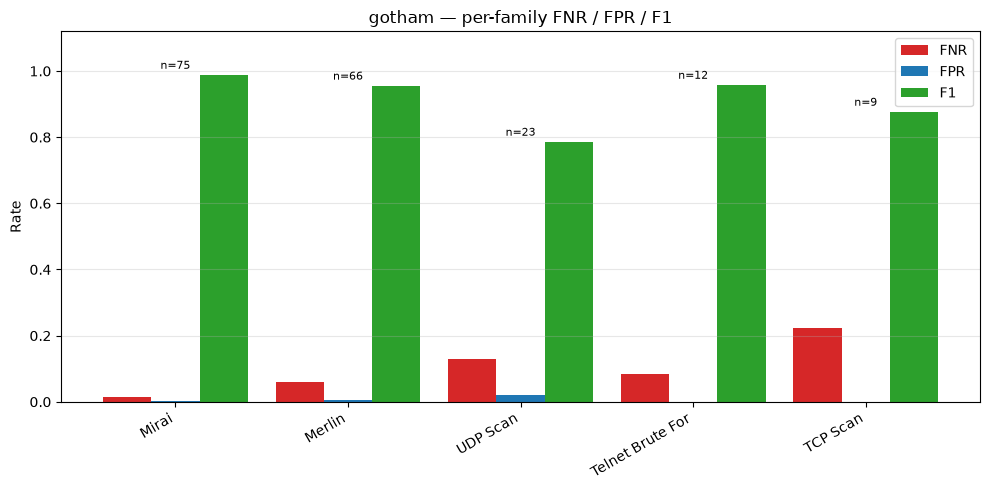

saved per_family_plots\gotham_per_family_bars.png


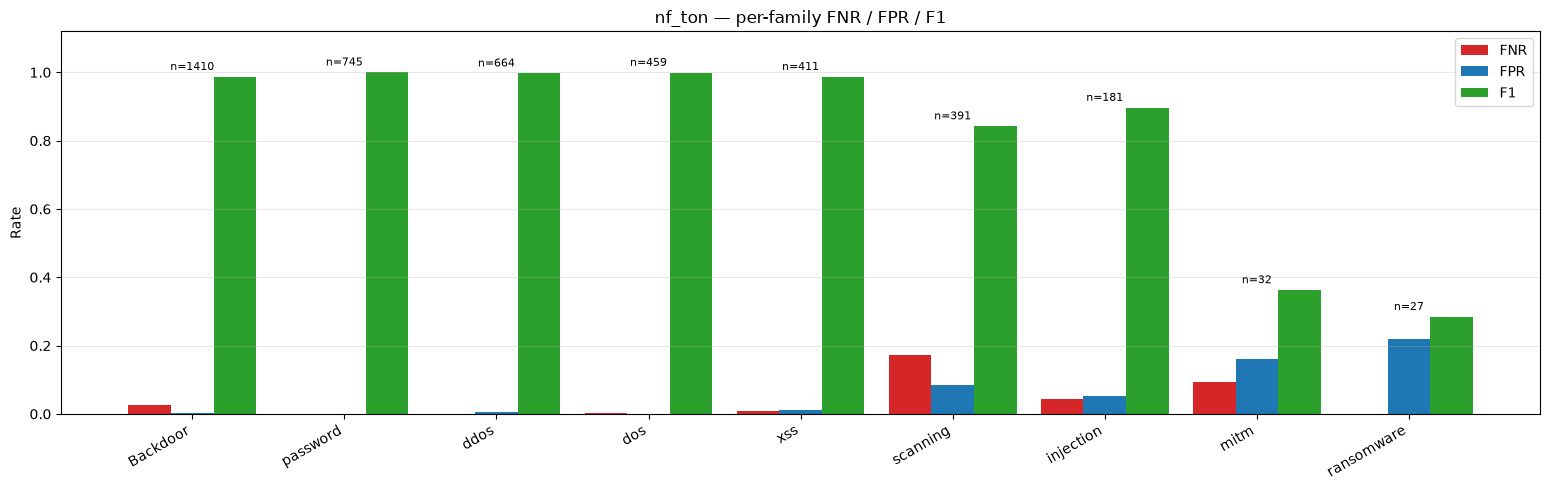

saved per_family_plots\nf_ton_per_family_bars.png


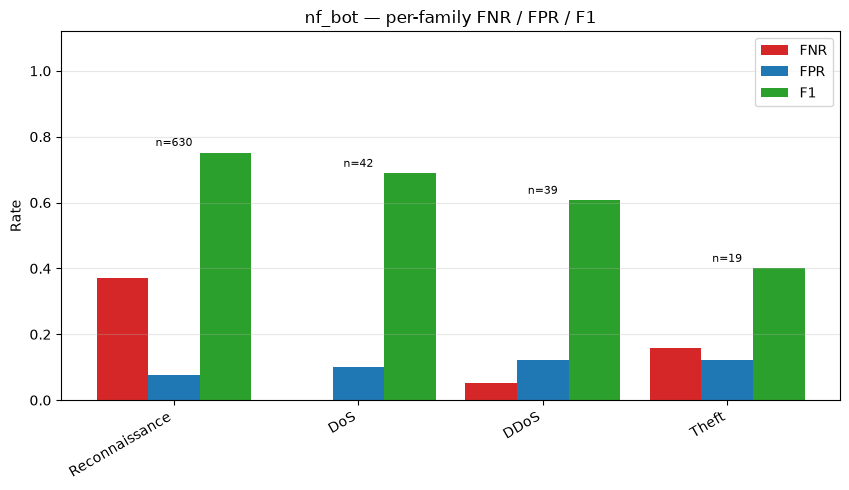

saved per_family_plots\nf_bot_per_family_bars.png


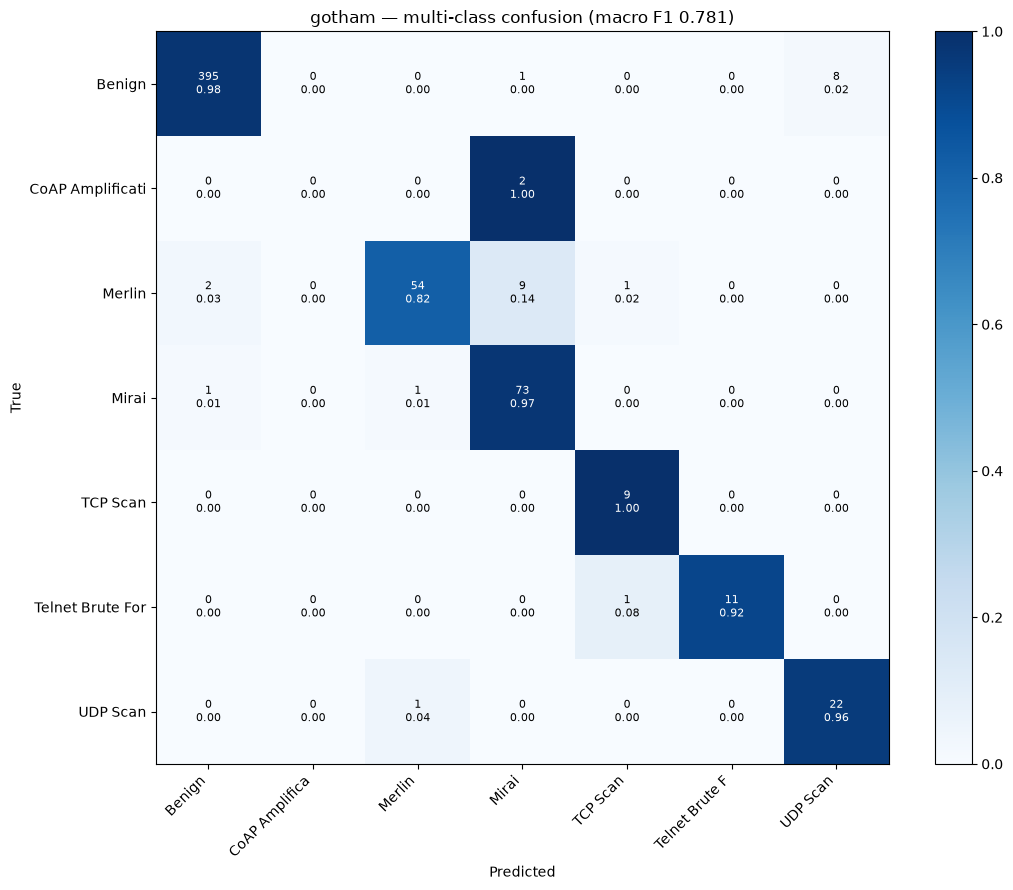

saved per_family_plots\gotham_multiclass_confusion.png


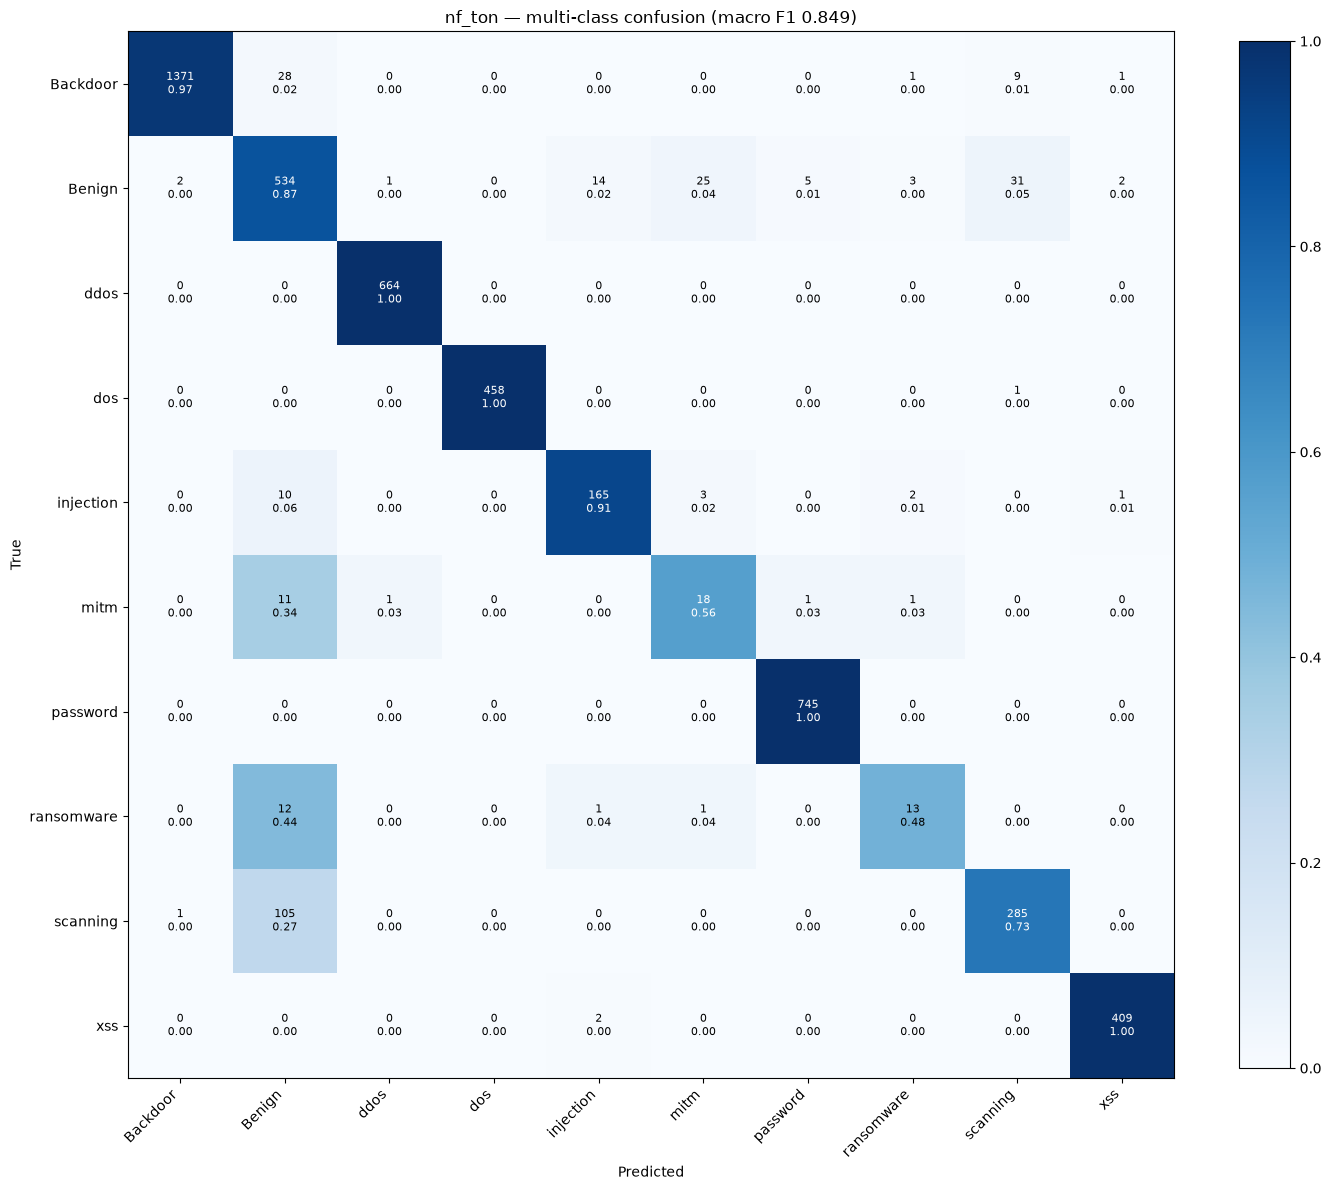

saved per_family_plots\nf_ton_multiclass_confusion.png


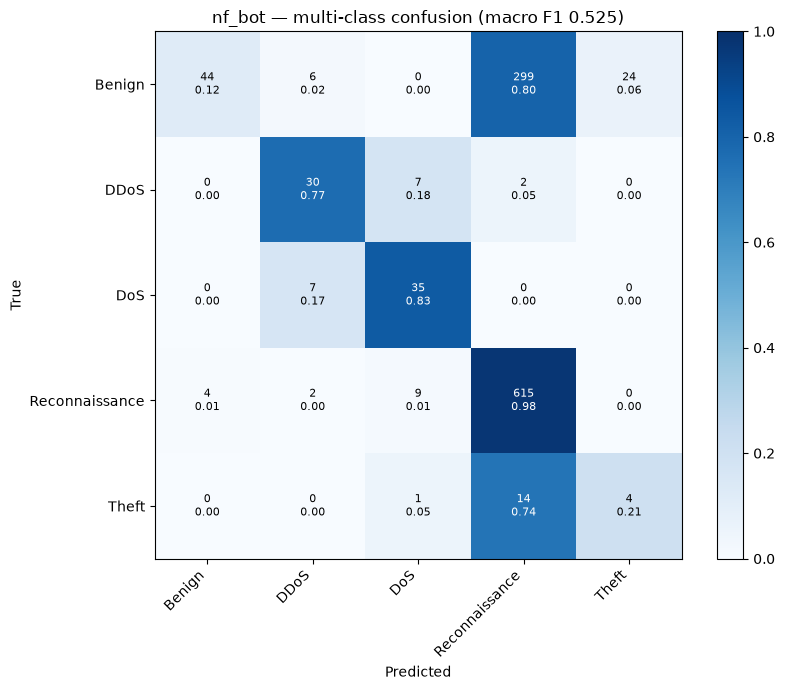

saved per_family_plots\nf_bot_multiclass_confusion.png

All plots in c:\Users\User\Desktop\MC-STGAT-IDS Experiment\MC-STGAT-IDS-V5\per_family_plots/


In [13]:
try:
    import matplotlib
    %matplotlib inline
    import matplotlib.pyplot as plt
    HAS_MPL = True
except Exception as e:
    print(f'[skip plots] matplotlib unavailable: {e}')
    HAS_MPL = False

if HAS_MPL:
    # ---- Fig 1: FNR / FPR / F1 bars per dataset ----
    for ds, res in PER_FAMILY_RESULTS.items():
        pf = res['per_family']
        if not pf: continue
        families = sorted(pf.keys(), key=lambda f: -pf[f]['n_test_pos'])
        fnr = [pf[f]['FNR'] for f in families]
        fpr = [pf[f]['FPR'] for f in families]
        f1  = [pf[f]['F1']  for f in families]
        n   = [pf[f]['n_test_pos'] for f in families]

        x = np.arange(len(families))
        w = 0.28
        fig, ax = plt.subplots(figsize=(1.4 * len(families) + 3, 5))
        ax.bar(x - w, fnr, width=w, label='FNR', color='#d62728')
        ax.bar(x,     fpr, width=w, label='FPR', color='#1f77b4')
        ax.bar(x + w, f1,  width=w, label='F1',  color='#2ca02c')
        for i, ni in enumerate(n):
            ax.text(x[i], max(fnr[i], fpr[i], f1[i]) + 0.02,
                    f"n={ni}", ha='center', fontsize=8)
        ax.set_xticks(x)
        ax.set_xticklabels([f[:16] for f in families],
                           rotation=30, ha='right')
        ax.set_ylim(0, 1.12)
        ax.set_ylabel('Rate')
        ax.set_title(f'{ds} — per-family FNR / FPR / F1')
        ax.grid(alpha=.3, axis='y')
        ax.legend(loc='upper right')
        plt.tight_layout()
        out = os.path.join(PLOT_ROOT, f'{ds}_per_family_bars.png')
        plt.savefig(out, dpi=140, bbox_inches='tight')
        plt.show()
        plt.close(fig)
        print(f'saved {out}')

    # ---- Fig 2: multi-class confusion matrix per dataset ----
    for ds, res in MULTICLASS_RESULTS.items():
        labels = res['labels']
        cm = np.array(res['confusion_matrix'])
        cmn = np.array(res['confusion_matrix_normalized'])
        fig, ax = plt.subplots(figsize=(1.1 * len(labels) + 3, 1.0 * len(labels) + 2))
        im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
        ax.set_xticks(range(len(labels)))
        ax.set_yticks(range(len(labels)))
        ax.set_xticklabels([l[:14] for l in labels],
                           rotation=45, ha='right')
        ax.set_yticklabels([l[:16] for l in labels])
        for i in range(len(labels)):
            for j in range(len(labels)):
                ax.text(j, i, f"{cm[i,j]}\n{cmn[i,j]:.2f}",
                        ha='center', va='center', fontsize=8,
                        color='white' if cmn[i,j] > 0.5 else 'black')
        ax.set_xlabel('Predicted'); ax.set_ylabel('True')
        ax.set_title(f'{ds} — multi-class confusion (macro F1 '
                     f'{res["macro_F1"]:.3f})')
        plt.colorbar(im, ax=ax, fraction=0.04)
        plt.tight_layout()
        out = os.path.join(PLOT_ROOT, f'{ds}_multiclass_confusion.png')
        plt.savefig(out, dpi=140, bbox_inches='tight')
        plt.show()
        plt.close(fig)
        print(f'saved {out}')

    print(f"\nAll plots in {os.path.abspath(PLOT_ROOT)}/")